In [1]:
import pandas as pd

df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv")

df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [2]:
print("Jumlah missing value setiap kolom:")
print(df.isnull().sum())

Jumlah missing value setiap kolom:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


In [3]:
# Mengisi missing value pada kolom kode_kasir
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK DIKETAHUI")

# Memeriksa kembali missing value
print("Missing value setelah penanganan:")
print(df.isnull().sum())

Missing value setelah penanganan:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64


In [5]:
# Menghitung total pendapatan sebelum diskon
df["total_sebelum_diskon"] = df["jumlah"] * df["harga_satuan"]

# Menghitung pendapatan setelah diskon
df["pendapatan"] = (
    df["total_sebelum_diskon"]
    * (1 - df["diskon_persen"] / 100)
)

# Mengambil transaksi yang statusnya SELESAI
transaksi_selesai = df[df["status"] == "SELESAI"].copy()

# Mengubah tanggal menjadi format datetime
transaksi_selesai["tanggal"] = pd.to_datetime(
    transaksi_selesai["tanggal"],
    format="mixed",
    dayfirst=True
)

# Mengelompokkan pendapatan berdasarkan tahun
transaksi_selesai["tahun"] = transaksi_selesai["tanggal"].dt.year

pendapatan_tahunan = transaksi_selesai.groupby("tahun")["pendapatan"].sum()

print("Pendapatan tahun 2024: Rp{:,.0f}".format(pendapatan_tahunan.get(2024, 0)))
print("Pendapatan tahun 2025: Rp{:,.0f}".format(pendapatan_tahunan.get(2025, 0)))

Pendapatan tahun 2024: Rp387,205,875
Pendapatan tahun 2025: Rp257,697,450


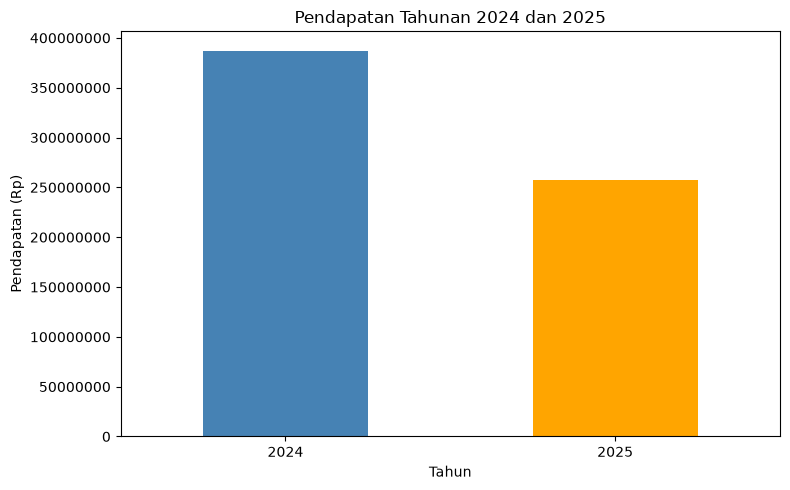

In [10]:
import matplotlib.pyplot as plt

pendapatan_tahunan.plot(
    kind="bar",
    color=["steelblue", "orange"],
    figsize=(8, 5)
)

plt.title("Pendapatan Tahunan 2024 dan 2025")
plt.xlabel("Tahun")
plt.ylabel("Pendapatan (Rp)")
plt.xticks(rotation=0)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [11]:
hasil = pendapatan_tahunan.reset_index()
hasil.columns = ["tahun", "pendapatan"]

hasil.to_csv("hasil_pendapatan_tahunan.csv", index=False)

print("Hasil berhasil disimpan!")

Hasil berhasil disimpan!
